# 🧬 Proje 3 · Bölüm 3 — DNA dizisini görüntüye çevirmek: Kaos Oyunu Gösterimi
**Seviye: Orta → İleri**

DNA bir harf dizisidir: `ATGCCCCAACTAAATACT…`. Görüntü işleme yöntemlerini genetik diziye uygulamanın zarif bir yolu, diziyi **bir resme** dönüştürmektir.

**Kaos Oyunu Gösterimi (Chaos Game Representation, CGR — Jeffrey, 1990):**
1. Bir karenin dört köşesine A, C, G, T yerleştirilir.
2. Karenin ortasından başlanır.
3. Dizideki her harf için, bulunduğun nokta ile o harfin köşesinin **tam ortasına** gidilir ve bir nokta konur.

Ortaya çıkan desen, dizinin tüm **k-mer** (k harflik alt dizi) içeriğini tek bir resimde özetler: bir tür **"genomik parmak izi"**. Görüntüyü ızgaraya bölüp her hücredeki noktaları sayarsak **frekans-CGR (FCGR)** elde ederiz — artık sinir ağlarına verilebilecek bir görüntü!

**Veri seti:** İnsan (4.380), şempanze (1.682) ve köpek (820) protein kodlayan gen dizileri; 7 gen ailesine etiketli (G-proteine bağlı reseptörler, tirozin kinazlar, iyon kanalları, transkripsiyon faktörleri…). *Kaynak: Kaggle "DNA sequence dataset" (N. Singh), GitHub üzerinden.*

In [1]:
# Google Colab'da çalışıyorsanız proje klasörünü (zip) yükleyin
import os, sys
if "google.colab" in sys.modules and not os.path.exists("veri"):
    from google.colab import files
    print("Lütfen 03_Genetik.zip dosyasını seçin"); files.upload()
    !unzip -q -o 03_Genetik.zip
    %cd 03_Genetik
print("Çalışma klasörü:", os.getcwd())

Çalışma klasörü: /home/claude/SaglikYZ/03_Genetik


In [2]:
import os
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"
import numpy as np, pandas as pd, matplotlib.pyplot as plt, json, keras
from keras import layers
from dna_goruntu import cgr_noktalari, fcgr, fcgr_normalize, SINIFLAR
plt.rcParams["figure.dpi"] = 110

veri = {t: pd.read_csv(f"veri/dna/{t}_data.txt", sep="\t") for t in ["human", "chimp", "dog"]}
for t, d in veri.items():
    print(f"{t:6s}: {len(d):5d} dizi | medyan uzunluk {int(d.sequence.str.len().median())} nükleotit")
ozet = veri["human"]["class"].value_counts().sort_index()
ozet.index = [SINIFLAR[i] for i in ozet.index]; ozet.to_frame("İnsan dizisi sayısı")

I0000 00:00:1791823230.178814   30170 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


I0000 00:00:1791823231.649956   30170 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


human :  4380 dizi | medyan uzunluk 865 nükleotit
chimp :  1682 dizi | medyan uzunluk 1569 nükleotit
dog   :   820 dizi | medyan uzunluk 1627 nükleotit


,İnsan dizisi sayısı
G-proteine bağlı reseptör,531
Tirozin kinaz,534
Tirozin fosfataz,349
Sentetaz,672
Sentaz,711
İyon kanalı,240
Transkripsiyon faktörü,1343


## 1. Kaos oyununu adım adım oynayalım

Dizinin başı: ATGTGTGGCATTTGGGCGCTGTTTGGCAGTGATGATTGCCTTTCTGTTCAGTGTCTGAGT ...


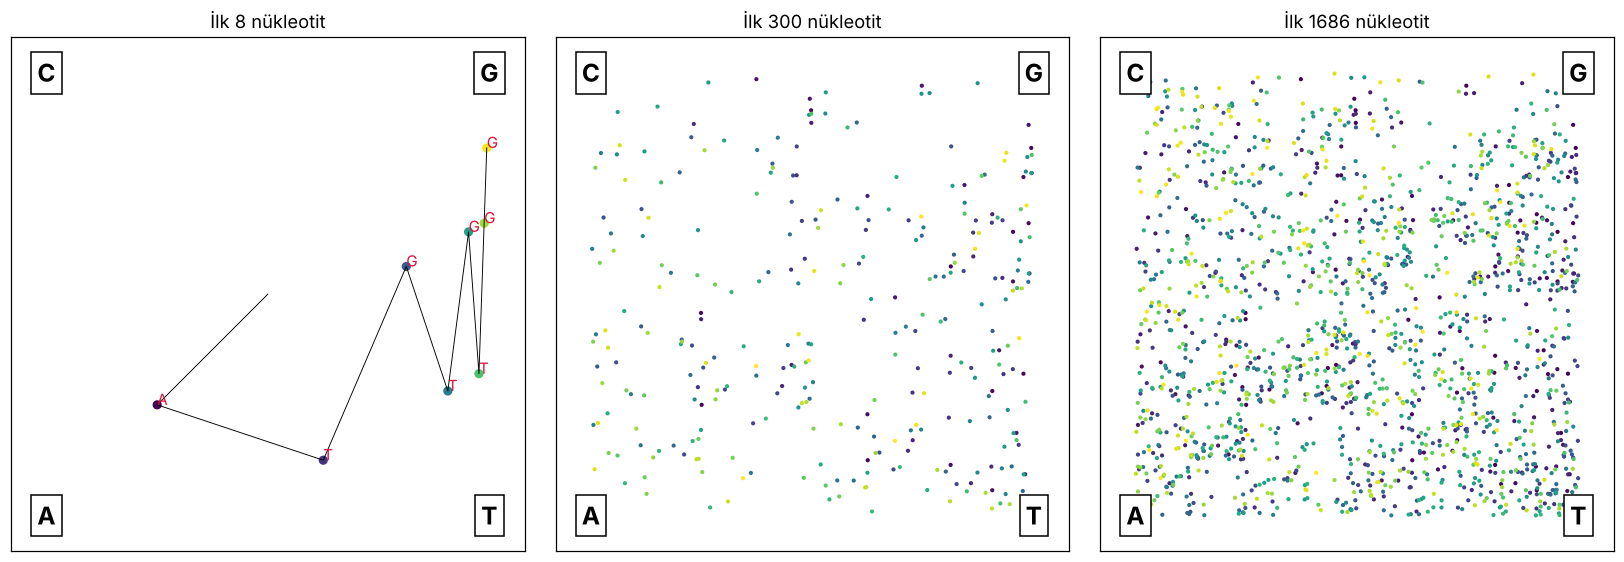

In [3]:
dizi = veri["human"].sequence[veri["human"].sequence.str.len().between(1500, 3000)].iloc[0]
print("Dizinin başı:", dizi[:60], "...")
nok = cgr_noktalari(dizi)
fig, ax = plt.subplots(1, 3, figsize=(15, 5))
for a, n in zip(ax, [8, 300, len(nok)]):
    n = min(n, len(nok))
    a.scatter(nok[:n, 0], nok[:n, 1], s=3 if n > 50 else 25, c=np.arange(n), cmap="viridis")
    if n <= 8:
        a.plot(np.r_[0.5, nok[:n, 0]], np.r_[0.5, nok[:n, 1]], "k-", lw=.6)
        for i in range(n): a.annotate(dizi[i], nok[i], fontsize=10, color="crimson")
    for h, (x, y) in {"A": (0, 0), "C": (0, 1), "G": (1, 1), "T": (1, 0)}.items():
        a.text(x, y, h, fontsize=16, fontweight="bold", ha="center", va="center", bbox=dict(fc="w", ec="k"))
    a.set_xlim(-.08, 1.08); a.set_ylim(-.08, 1.08); a.set_aspect("equal"); a.set_xticks([]); a.set_yticks([])
    a.set_title(f"İlk {n} nükleotit")
plt.tight_layout(); plt.show()

**Neden desen oluşuyor?** Karenin her çeyreği dizinin **son harfine**, her alt çeyreği **son iki harfine** karşılık gelir. Örneğin sağ alt köşenin hemen üstü "…TG" ile biten konumlardır. İnsan genomunda **CG** dinükleotidi (CpG) nadir olduğu için görüntüde karakteristik **boş çizgiler** belirir.

## 2. Frekans-CGR: diziden sabit boyutlu bir görüntü
k = 6 seçersek 4⁶ = 4.096 farklı 6-mer → **64×64 piksellik** bir görüntü. Dizi 200 ya da 18.000 harf olsun, görüntü hep aynı boyuttadır.

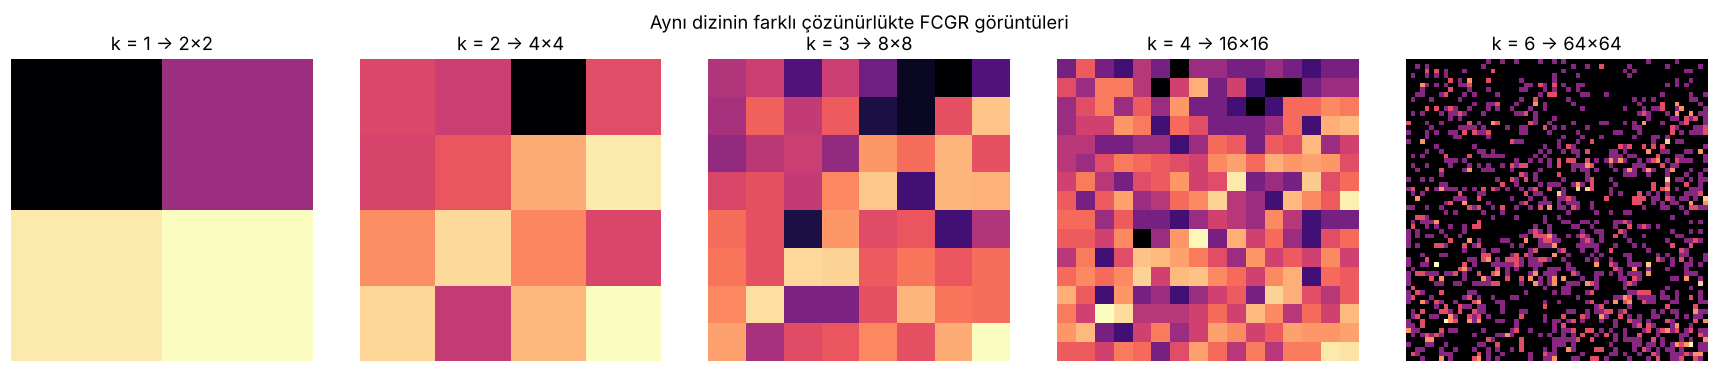

In [4]:
fig, ax = plt.subplots(1, 5, figsize=(16, 3.4))
for a, k in zip(ax, [1, 2, 3, 4, 6]):
    a.imshow(fcgr_normalize(fcgr(dizi, k)), cmap="magma"); a.set_title(f"k = {k} → {2**k}×{2**k}"); a.axis("off")
plt.suptitle("Aynı dizinin farklı çözünürlükte FCGR görüntüleri"); plt.tight_layout(); plt.show()

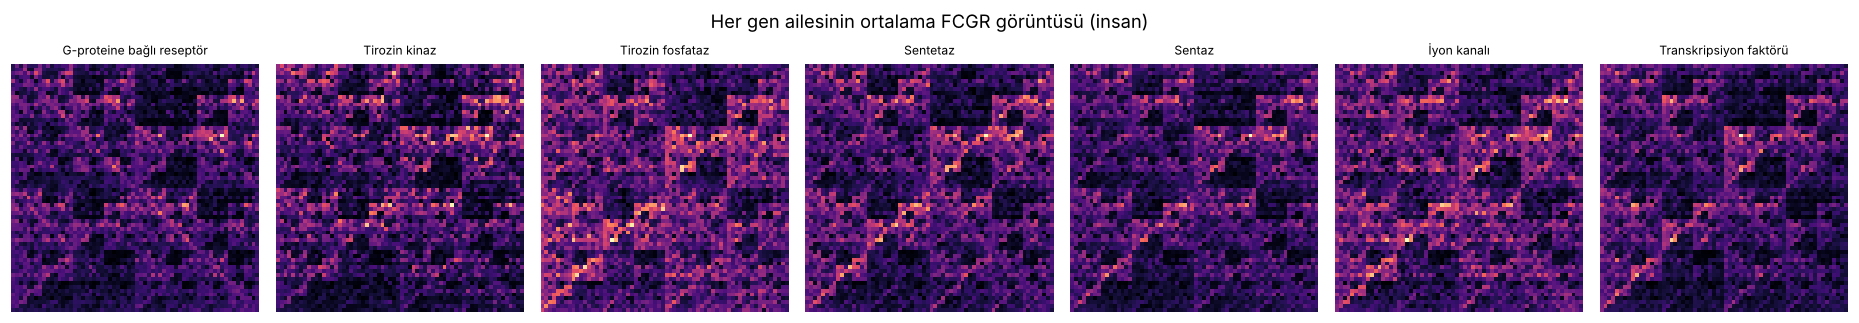

In [5]:
# Tüm dizileri 64x64 FCGR görüntüsüne çevirelim
F = {t: np.stack([fcgr(s, 6) for s in d.sequence]) for t, d in veri.items()}
y = {t: d["class"].values for t, d in veri.items()}

fig, ax = plt.subplots(1, 7, figsize=(17, 3))
for k in range(7):
    ort = np.mean([fcgr_normalize(m) for m in F["human"][y["human"] == k]], axis=0)
    ax[k].imshow(ort, cmap="magma"); ax[k].set_title(SINIFLAR[k], fontsize=8); ax[k].axis("off")
plt.suptitle("Her gen ailesinin ortalama FCGR görüntüsü (insan)"); plt.tight_layout(); plt.show()

## 3. Veri sızıntısı tuzağı: neredeyse aynı diziler 🔎
Bu veri setinde aynı genin parçaları ya da birebir aynı diziler **çok sayıda** bulunuyor. Rastgele bölersek, test setindeki dizinin neredeyse aynısı eğitimde olur ve model **ezberleyerek** yüksek başarı gösterir. Bunu ölçmek için dizileri k-mer benzerliğine göre **gruplayıp** aynı grubu tek tarafa koyacağız.

In [6]:
from scipy.sparse import csr_matrix
from scipy.sparse.csgraph import connected_components
V = F["human"].reshape(len(F["human"]), -1)
Vn = V / np.linalg.norm(V, axis=1, keepdims=True).clip(1e-9)
benzer = (Vn @ Vn.T) > 0.9                         # kosinüs benzerliği > 0,9 → aynı grup
_, grup = connected_components(csr_matrix(benzer))
print(f"Birebir aynı dizi: {veri['human'].sequence.duplicated().sum()} | 4.380 dizi → {grup.max()+1} benzerlik grubu")

from sklearn.model_selection import train_test_split, GroupShuffleSplit
bolunmeler = {
    "Rastgele bölme": train_test_split(np.arange(len(V)), test_size=0.2, stratify=y["human"], random_state=0),
    "Grup bölme (sızıntısız)": next(GroupShuffleSplit(1, test_size=0.2, random_state=0).split(V, y["human"], grup)),
}

Birebir aynı dizi: 751 | 4.380 dizi → 2306 benzerlik grubu


## 4. Üç yaklaşımı karşılaştıralım
| Model | Ne yapar? |
|---|---|
| **En yakın komşu (1-NN)** | "Eğitimdeki en benzer dizinin ailesi neyse o" — saf ezber |
| **Lojistik regresyon (FCGR pikselleri)** | 4.096 pikselin her birine (her 6-mer'e) bir ağırlık verir |
| **CNN (FCGR görüntüsü)** | Görüntüdeki yerel desenleri öğrenir |

Ayrıca modeli **insan** dizileriyle eğitip **şempanze** ve **köpek** dizilerinde test edeceğiz (türler arası genelleme).

In [7]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression

def frekans(M):                                   # her dizinin 6-mer frekansları (×4096 → ortalama 1)
    M = M.reshape(len(M), -1).astype(np.float64)
    return M / M.sum(1, keepdims=True).clip(1) * 4096

def kucuk_cnn():
    keras.utils.set_random_seed(0)
    g = keras.Input((64, 64, 1)); x = g
    for f in [16, 32, 64]:
        x = layers.Conv2D(f, 3, padding="same", activation="relu")(x); x = layers.MaxPooling2D()(x)
    x = layers.Conv2D(64, 3, padding="same", activation="relu")(x); x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(0.3)(x); c = layers.Dense(7, activation="softmax")(x)
    m = keras.Model(g, c); m.compile(keras.optimizers.Adam(1e-3), "sparse_categorical_crossentropy", metrics=["accuracy"])
    return m

goruntu = {t: np.stack([fcgr_normalize(m) for m in F[t]])[..., None] for t in F}
sonuc, modeller = [], {}
for bad, (tr, te) in bolunmeler.items():
    yh = y["human"]
    knn = KNeighborsClassifier(1, metric="cosine").fit(V[tr], yh[tr])
    lr = LogisticRegression(max_iter=3000, C=100).fit(frekans(F["human"][tr]), yh[tr])
    cnn = kucuk_cnn()
    cnn.fit(goruntu["human"][tr], yh[tr], epochs=40, batch_size=32, validation_split=0.1, verbose=0,
            callbacks=[keras.callbacks.EarlyStopping(patience=8, restore_best_weights=True)])
    modeller[bad] = {"lr": lr}
    for mad, tahmin in [("1-NN (ezber)", lambda t: knn.predict(F[t].reshape(len(F[t]), -1))),
                        ("Lojistik regresyon (FCGR)", lambda t: lr.predict(frekans(F[t]))),
                        ("CNN (FCGR görüntüsü)", lambda t: cnn.predict(goruntu[t], verbose=0).argmax(1))]:
        satir = {"Bölme": bad, "Model": mad, "İnsan (test)": np.mean(tahmin("human")[te] == yh[te])}
        satir["Şempanze"] = np.mean(tahmin("chimp") == y["chimp"]); satir["Köpek"] = np.mean(tahmin("dog") == y["dog"])
        sonuc.append(satir)
tablo = pd.DataFrame(sonuc).set_index(["Bölme", "Model"]).round(3)
tablo

İnsan (test)  Şempanze  \
Bölme                   Model                                               
Rastgele bölme          1-NN (ezber)                      0.962     0.983   
                        Lojistik regresyon (FCGR)         0.906     0.975   
                        CNN (FCGR görüntüsü)              0.639     0.725   
Grup bölme (sızıntısız) 1-NN (ezber)                      0.830     0.929   
                        Lojistik regresyon (FCGR)         0.790     0.944   
                        CNN (FCGR görüntüsü)              0.506     0.683   

                                                   Köpek  
Bölme                   Model                             
Rastgele bölme          1-NN (ezber)               0.949  
                        Lojistik regresyon (FCGR)  0.854  
                        CNN (FCGR görüntüsü)       0.613  
Grup bölme (sızıntısız) 1-NN (ezber)               0.873  
                        Lojistik regresyon (FCGR)  0.843  
                        CNN (FCGR görüntüsü)       0.546

### Yorum — makale yazarken mutlaka bakılması gereken üç ders
1. **Veri sızıntısı:** Rastgele bölmede başarı belirgin biçimde yüksek; grup bölmede düşüyor. Bu veri setiyle yayımlanmış ve %95+ doğruluk bildiren pek çok çalışma bu etkiyi hesaba katmıyor olabilir.
2. **Türler arası test şaşırtıcı derecede yüksek — neden?** Protein kodlayan genler memeliler arasında güçlü biçimde **korunmuştur**: şempanze ve köpek dizilerinin çoğunun insandaki karşılığı (*ortoloğu*) eğitim setinde zaten var. Yani bu da bir tür "benzerlik sızıntısı"dır. Gerçek genelleme için diziler **gen/ortolog gruplarına** göre bölünmelidir.
3. **"Görüntüye çevirmek" her zaman en iyi değildir:** Bu problemde FCGR pikselleri üzerinde basit bir lojistik regresyon, küçük CNN'den daha iyi. CNN'in havuzlama katmanları komşu k-mer'leri birleştirerek tam k-mer kimliğini bulanıklaştırıyor olabilir. **Temsil (representation) seçimi, model seçimi kadar önemlidir.**

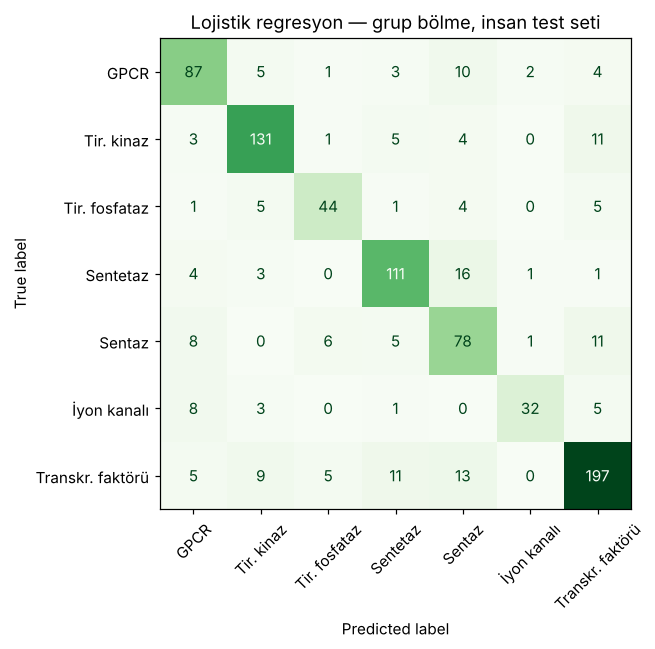

In [8]:
from sklearn.metrics import ConfusionMatrixDisplay
lr = modeller["Grup bölme (sızıntısız)"]["lr"]
tr, te = bolunmeler["Grup bölme (sızıntısız)"]
fig, ax = plt.subplots(figsize=(7, 6))
kisa = ["GPCR", "Tir. kinaz", "Tir. fosfataz", "Sentetaz", "Sentaz", "İyon kanalı", "Transkr. faktörü"]
ConfusionMatrixDisplay.from_predictions(y["human"][te], lr.predict(frekans(F["human"][te])), display_labels=kisa,
                                        cmap="Greens", colorbar=False, ax=ax, xticks_rotation=45)
ax.set_title("Lojistik regresyon — grup bölme, insan test seti"); plt.tight_layout(); plt.show()

## 5. Model hangi k-mer'lere bakıyor?
Lojistik regresyonun ağırlıklarını 64×64 FCGR ızgarasına geri yerleştirirsek, her gen ailesi için **hangi 6-mer'lerin** o aile lehine "oy verdiğini" görürüz.

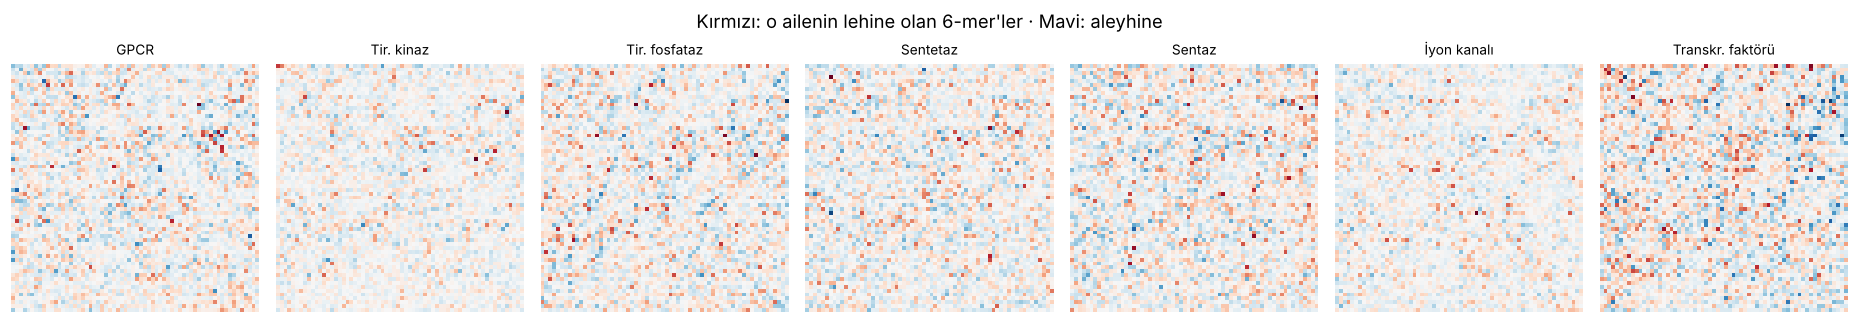

G-proteine bağlı reseptör   : CACAGG, TCGCTG, GGCCAC, GTCCTG, CTGCTG, CTCTTC
İyon kanalı                 : CATCCT, TTCATC, ATCTTC, TCTTCA, GCTGGC, ATTTTC
Transkripsiyon faktörü      : CGGCGG, CCCTCC, CACAGA, CTCCCC, GCGGCG, CCTTGG


In [9]:
fig, ax = plt.subplots(1, 7, figsize=(17, 3))
for k in range(7):
    w = lr.coef_[k].reshape(64, 64); s = np.abs(w).max()
    ax[k].imshow(w, cmap="RdBu_r", vmin=-s, vmax=s); ax[k].set_title(kisa[k], fontsize=9); ax[k].axis("off")
plt.suptitle("Kırmızı: o ailenin lehine olan 6-mer'ler · Mavi: aleyhine"); plt.tight_layout(); plt.show()

# En etkili 6-mer'ler (ızgara konumundan diziye geri çeviriyoruz)
def konum_to_kmer(r, c, k=6):
    py, px = 63 - r, c
    return "".join({(0, 0): "A", (0, 1): "C", (1, 1): "G", (1, 0): "T"}[((px >> j) & 1, (py >> j) & 1)] for j in range(k))
for k in [0, 5, 6]:
    en = np.argsort(-lr.coef_[k])[:6]
    print(f"{SINIFLAR[k]:28s}:", ", ".join(konum_to_kmer(i // 64, i % 64) for i in en))

## 6. Telefona aktarma
Uygulama için tüm insan verisiyle (grup bölmenin eğitim kısmı) eğitilmiş lojistik regresyonu dışa aktarıyoruz: 4.096 × 7 ağırlık + 7 sabit terim.

In [10]:
import base64, subprocess, shutil
os.makedirs("mobil/www", exist_ok=True); os.makedirs("model", exist_ok=True)
b64 = lambda a: base64.b64encode(np.ascontiguousarray(a, dtype=np.float32).tobytes()).decode()
disa = {"k": 6, "siniflar": SINIFLAR, "W": b64(lr.coef_.T), "b": b64(lr.intercept_),
        "dogruluk": {c: float(tablo.loc[("Grup bölme (sızıntısız)", "Lojistik regresyon (FCGR)"), c]) for c in ["İnsan (test)", "Şempanze", "Köpek"]}}
open("mobil/www/dna_model.js", "w").write("window.DNA_MODEL = " + json.dumps(disa, ensure_ascii=False) + ";\n")
json.dump({k: v for k, v in disa.items() if k not in ("W", "b")}, open("model/dna_lr_bilgi.json", "w"), ensure_ascii=False, indent=1)

# Örnek diziler: grup bölmenin TEST kısmından (her aileden bir insan dizisi) + bir şempanze + bir köpek
rng = np.random.default_rng(1); ornekler = []
for k in range(7):
    aday = [i for i in te if y["human"][i] == k and 300 <= len(veri["human"].sequence[i]) <= 2500]
    i = int(rng.choice(aday)); ornekler.append({"ad": f"İnsan · {SINIFLAR[k]}", "sinif": k, "dizi": veri["human"].sequence[i]})
for t, ad in [("chimp", "Şempanze"), ("dog", "Köpek")]:
    i = int(np.where(veri[t].sequence.str.len().between(300, 2500))[0][3])
    ornekler.append({"ad": f"{ad} · {SINIFLAR[y[t][i]]}", "sinif": int(y[t][i]), "dizi": veri[t].sequence[i]})
open("mobil/www/ornek_dna.js", "w").write("window.ORNEK_DNA = " + json.dumps(ornekler, ensure_ascii=False) + ";\n")

# Doğrulama: JS ile aynı olasılıklar mı?
if shutil.which("node"):
    test_diziler = [o["dizi"] for o in ornekler]
    betik = """global.window=global; global.atob=s=>Buffer.from(s,'base64').toString('binary'); const fs=require('fs');
    eval(fs.readFileSync('mobil/www/dna_model.js','utf8')); eval(fs.readFileSync('mobil/www/dna.js','utf8'));
    const d=JSON.parse(fs.readFileSync(0,'utf8')); console.log(JSON.stringify(d.map(s=>DNA.tahmin(s).olasilik)));"""
    js = np.array(json.loads(subprocess.run(["node", "-e", betik], input=json.dumps(test_diziler), capture_output=True, text=True, check=True).stdout))
    py = lr.predict_proba(frekans(np.stack([fcgr(s, 6) for s in test_diziler])))
    print(f"JS ve Python olasılık farkı (en büyük): {np.abs(js - py).max():.1e}")
print("Örnekler:", [o["ad"] for o in ornekler])

JS ve Python olasılık farkı (en büyük): 4.2e-08
Örnekler: ['İnsan · G-proteine bağlı reseptör', 'İnsan · Tirozin kinaz', 'İnsan · Tirozin fosfataz', 'İnsan · Sentetaz', 'İnsan · Sentaz', 'İnsan · İyon kanalı', 'İnsan · Transkripsiyon faktörü', 'Şempanze · Transkripsiyon faktörü', 'Köpek · G-proteine bağlı reseptör']


## ✅ Çıkarımlar
* Bir DNA dizisi, **Kaos Oyunu** ile sabit boyutlu bir görüntüye dönüştürülebilir; bu, görüntü işleme araçlarını genomiğe taşımanın bir yoludur (virüs sınıflandırma, tür tanımlama, metagenomik).
* Gen ailesi tahmininde **veri sızıntısını** önlemek, başarıyı gerçekçi ölçmenin önkoşuludur.
* Basit modeller güçlü olabilir; derin öğrenme, temsil uygun olduğunda farkı yaratır.

💡 **Araştırma fikirleri**
1. Patojen tanımlama: SARS-CoV-2 varyantlarının / bakteri türlerinin FCGR görüntüleriyle hızlı sınıflandırılması (NCBI verileri).
2. Aynı veri setinde **sızıntısız** yeniden değerlendirme: literatürdeki raporlanan başarıların ne kadarının ezberden kaynaklandığını gösteren bir **metodolojik çalışma**.
3. FCGR + CNN ile **varyant patojenite** tahmini (ClinVar: zararlı / zararsız varyant çevresindeki dizi).